# Day 19 — Research Methodology & Data Analysis\n\n**Practice project:** E-commerce satisfaction and repeat-purchase intention.\n\n> Synthetic data only; do not report it as real customer evidence.

## 1. Research framework\nResearch question: Does satisfaction relate to repeat-purchase intention?\n\nH0: lower- and higher-satisfaction groups have equal mean repeat intention.\nH1: group means differ. Alpha = 0.05, two-sided. For this cross-sectional project, interpret influence as association.

In [1]:
from pathlib import Path
import pandas as pd 
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent
df = pd.read_csv(ROOT / 'data' / 'ecommerce_satisfaction_sample.csv')
df.head()

,respondent_id,age_band,purchase_frequency,satisfaction,repeat_intention,delivery_rating,consent
0,SYN001,55+,1-2 times/month,4,4,3,True
1,SYN002,55+,1-2 times/month,3,2,3,True
2,SYN003,18-24,3-5 times/month,3,3,3,True
3,SYN004,18-24,6+ times/month,5,5,5,True
4,SYN005,18-24,3-5 times/month,2,1,2,True


## 2. Data quality checks\nInspect shape, data types, missingness, duplicates, and valid Likert ranges before analysis.

In [2]:
print('Shape:', df.shape)
print(df.dtypes)
print('Missing values:\\n', df.isna().sum())
print('Duplicate rows:', df.duplicated().sum())
for col in ['satisfaction','repeat_intention','delivery_rating']:
        assert df[col].dropna().between(1,5).all()
print('Range checks passed')

Shape: (120, 7)
respondent_id           str
age_band                str
purchase_frequency      str
satisfaction          int64
repeat_intention      int64
delivery_rating       int64
consent                bool
dtype: object
Missing values:\n respondent_id         0
age_band              0
purchase_frequency    0
satisfaction          0
repeat_intention      0
delivery_rating       0
consent               0
dtype: int64
Duplicate rows: 0
Range checks passed


## 3. Descriptive statistics\nLikert items are ordinal; treating them as numeric is a classroom simplification. A real analysis should justify measurement and summarize distributions.

In [3]:
df[['satisfaction','repeat_intention','delivery_rating']].describe().T

,count,mean,std,min,25%,50%,75%,max
satisfaction,120.0,3.616667,1.093782,1.0,3.0,4.0,4.0,5.0
repeat_intention,120.0,3.633333,0.986747,1.0,3.0,4.0,4.0,5.0
delivery_rating,120.0,3.450000,1.187116,1.0,3.0,4.0,4.0,5.0


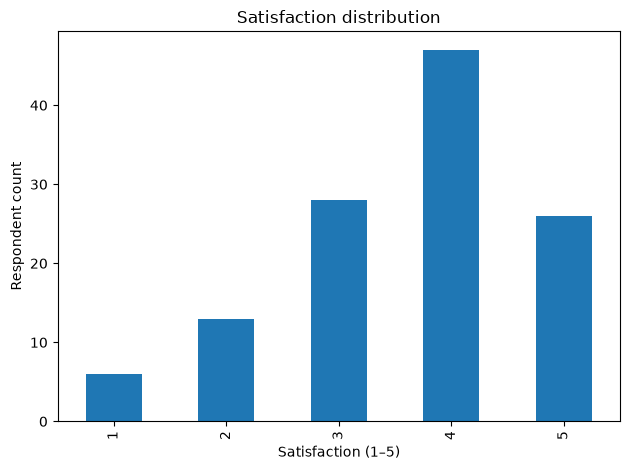

In [4]:
df['satisfaction'].value_counts().sort_index().plot(kind='bar', title='Satisfaction distribution')
plt.xlabel('Satisfaction (1–5)'); plt.ylabel('Respondent count'); plt.tight_layout(); plt.show()

## 4. Pearson correlation\nPearson r estimates linear association and does not prove causality. Consider Spearman correlation for ordinal data.

In [5]:
valid = df[['satisfaction','repeat_intention']].dropna()
r = stats.pearsonr(valid.satisfaction, valid.repeat_intention)
print(f'Pearson r={r.statistic:.3f}; p={r.pvalue:.6f}; n={len(valid)}')

Pearson r=0.554; p=0.000000; n=120


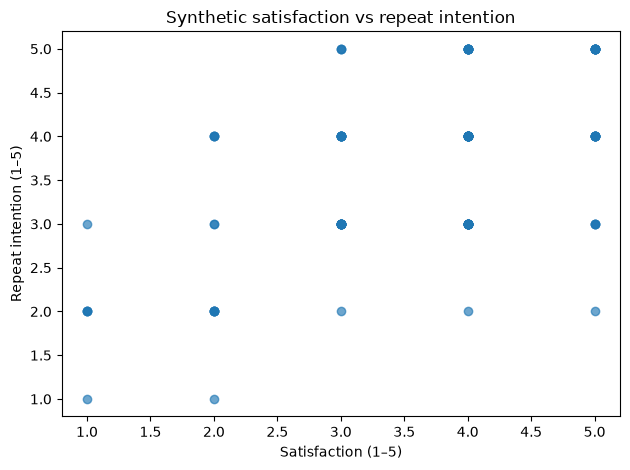

In [6]:
plt.scatter(valid.satisfaction, valid.repeat_intention, alpha=.65)
plt.xlabel('Satisfaction (1–5)'); plt.ylabel('Repeat intention (1–5)'); plt.title('Synthetic satisfaction vs repeat intention'); plt.tight_layout(); plt.show()

## 5. Welch independent-samples t-test\nPractice cutoff: satisfaction <=3 lower; >=4 higher. The cutoff is simplistic and must be predeclared and justified in real research. Welch's test does not assume equal variances.

In [7]:
df['group'] = np.where(df.satisfaction <= 3, 'Lower (<=3)', 'Higher (>=4)')
lower = df.loc[df.group == 'Lower (<=3)', 'repeat_intention'].dropna()
higher = df.loc[df.group == 'Higher (>=4)', 'repeat_intention'].dropna()
test = stats.ttest_ind(higher, lower, equal_var=False)
print('Lower:',len(lower),'mean',lower.mean())
print('Higher:',len(higher),'mean',higher.mean())
print(f'Welch t={test.statistic:.3f}; p={test.pvalue:.6f}')

Lower: 47 mean 3.106382978723404
Higher: 73 mean 3.9726027397260273
Welch t=4.995; p=0.000003


## 6. Effect size: Cohen's d\nA p-value is not the magnitude of an effect. Cohen's d here is higher-satisfaction minus lower-satisfaction, divided by pooled SD. Interpret magnitude in context.

In [8]:
n1,n2=len(higher),len(lower)
s1,s2=higher.std(ddof=1),lower.std(ddof=1)
pooled=np.sqrt(((n1-1)*s1**2+(n2-1)*s2**2)/(n1+n2-2))
d=(higher.mean()-lower.mean())/pooled
print(f'Cohen d={d:.3f}; significant at alpha=.05? {test.pvalue < .05}')

Cohen d=0.968; significant at alpha=.05? True


## 7. Interpretation and limitations\nWrite your own interpretation: sample size, means, correlation direction/magnitude, p-value, effect size, and practical meaning. Limitations: synthetic data, self-report, cross-sectional design, ordinal scales, arbitrary grouping, and no causal inference. Never present synthetic results as real shopper evidence.

## 8. Reproducible outputs\nFrom the project root, run `python src/analyze_research.py`. CSV summaries and a text report will be written to `outputs/`.